In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [30]:
GITHUB_LINK = 'https://github.com/csinva/gan-vae-pretrained-pytorch/tree/master'

In [20]:
class Generator(nn.Module):
    def __init__(self, ngpu, nc=1, nz=100, ngf=64):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is Z, going into a convolution
            nn.ConvTranspose2d(     nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2,     ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(    ngf,      nc, kernel_size=1, stride=1, padding=2, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output


class Discriminator(nn.Module):
    def __init__(self, ngpu, nc=1, ndf=64):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is (nc) x 64 x 64
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 32 x 32
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 16 x 16
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 8 x 8
            nn.Conv2d(ndf * 4, 1, 4, 2, 1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output.view(-1, 1).squeeze(1)

In [21]:
# loading weights for both generator and discriminator
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth -O netG.pth
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netD_epoch_99.pth -O netD.pth

--2025-11-23 21:21:02--  https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth [following]
--2025-11-23 21:21:02--  https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14306386 (14M) [application/octet-stream]
Saving to: ‘netG.pth’

netG.pth            100%[===================>]  13.64M  --.-KB/s    in 0.03s   



In [24]:
ngpu = 1
device = "cuda"

netG = Generator(ngpu=ngpu, nc=1, nz=100, ngf=64).to(device)
netD = Discriminator(ngpu=ngpu, nc=1, ndf=64).to(device)

G_state = torch.load("netG.pth", map_location=device)
D_state = torch.load("netD.pth", map_location=device)

netG.load_state_dict(G_state)
netD.load_state_dict(D_state)
print("Loaded MNIST DCGAN weights!")

Loaded MNIST DCGAN weights!


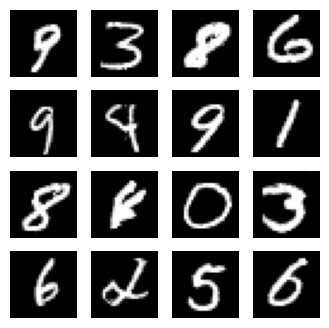

In [27]:
import matplotlib.pyplot as plt

z = torch.randn(16, 100, 1, 1).to(device)
fake = netG(z).detach().cpu()

plt.figure(figsize=(4,4))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(fake[i,0], cmap="gray")
    plt.axis("off")
plt.show()